<a href="https://colab.research.google.com/github/ASTER2005/ASTER2005/blob/main/Heart_Attack.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost lightgbm joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving train.csv to train.csv
Dataset loaded successfully!
Dataset shape: (7010, 26)


,Patient ID,Age,Sex,Cholesterol,Blood Pressure,Heart Rate,Diabetes,Family History,Smoking,Obesity,...,Sedentary Hours Per Day,Income,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Heart Attack Risk,starting_time,ending_time,measurement_interval_minutes
0,RDG0550,33,Male,200,129/90,48,0,1,1,1,...,0.138443,184066,30.449815,63,6,7,1,13:49:00,13:54:00,5
1,NMA3851,56,Female,262,159/105,46,1,0,1,0,...,0.369552,211755,34.973685,333,7,8,1,11:48:00,11:53:00,5
2,TUI5807,19,Female,140,161/109,54,0,1,0,0,...,8.646334,252203,30.554246,537,2,10,0,22:00:00,22:05:00,5
3,YYT5016,50,Female,163,120/62,53,0,1,1,1,...,1.107884,121954,35.390265,591,0,9,1,04:32:00,04:37:00,5
4,ZAC5937,89,Female,144,153/110,92,1,0,1,0,...,1.337570,180121,39.575483,145,2,5,1,01:11:00,01:16:00,5


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nTarget Distribution:")
print(df["Heart Attack Risk"].value_counts())

print("\nTarget Percentage:")
print(df["Heart Attack Risk"].value_counts(normalize=True) * 100)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7010 entries, 0 to 7009
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Patient ID                       7010 non-null   object 
 1   Age                              7010 non-null   int64  
 2   Sex                              7010 non-null   object 
 3   Cholesterol                      7010 non-null   int64  
 4   Blood Pressure                   7010 non-null   object 
 5   Heart Rate                       7010 non-null   int64  
 6   Diabetes                         7010 non-null   int64  
 7   Family History                   7010 non-null   int64  
 8   Smoking                          7010 non-null   int64  
 9   Obesity                          7010 non-null   int64  
 10  Alcohol Consumption              7010 non-null   int64  
 11  Exercise Hours Per Week          7010 non-null   float64
 12 

In [4]:
data = df.copy()

data = data.drop_duplicates()

bp = data["Blood Pressure"].astype(str).str.extract(
    r"^\s*(\d+(?:\.\d+)?)\s*/\s*(\d+(?:\.\d+)?)\s*$"
)

data["Systolic BP"] = pd.to_numeric(bp[0], errors="coerce")
data["Diastolic BP"] = pd.to_numeric(bp[1], errors="coerce")

data.drop(columns=["Blood Pressure"], inplace=True)

columns_to_remove = [
    "Patient ID",
    "starting_time",
    "ending_time",
    "measurement_interval_minutes"
]

data.drop(
    columns=[c for c in columns_to_remove if c in data.columns],
    inplace=True
)

X = data.drop(columns=["Heart Attack Risk"])
y = data["Heart Attack Risk"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (7010, 22)
Target shape: (7010,)

Feature columns:
['Age', 'Sex', 'Cholesterol', 'Heart Rate', 'Diabetes', 'Family History', 'Smoking', 'Obesity', 'Alcohol Consumption', 'Exercise Hours Per Week', 'Diet', 'Previous Heart Problems', 'Medication Use', 'Stress Level', 'Sedentary Hours Per Day', 'Income', 'BMI', 'Triglycerides', 'Physical Activity Days Per Week', 'Sleep Hours Per Day', 'Systolic BP', 'Diastolic BP']


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 5608
Testing records: 1402


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Age', 'Cholesterol', 'Heart Rate', 'Diabetes', 'Family History', 'Smoking', 'Obesity', 'Alcohol Consumption', 'Exercise Hours Per Week', 'Previous Heart Problems', 'Medication Use', 'Stress Level', 'Sedentary Hours Per Day', 'Income', 'BMI', 'Triglycerides', 'Physical Activity Days Per Week', 'Sleep Hours Per Day', 'Systolic BP', 'Diastolic BP']
Categorical features: ['Sex', 'Diet']


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        verbosity=-1,
        random_state=42,
        n_jobs=-1
    )
}

print("Five models are ready!")

Five models are ready!


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

results = []
trained_models = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "Specificity": specificity,
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_prob),
        "PR AUC": average_precision_score(y_test, y_prob)
    })

    trained_models[name] = pipeline

    print(f"{name} completed successfully!")


results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
display(results_df.round(4))


Training Logistic Regression...
Logistic Regression completed successfully!

Training Random Forest...
Random Forest completed successfully!

Training SVM...
SVM completed successfully!

Training XGBoost...
XGBoost completed successfully!

Training LightGBM...
LightGBM completed successfully!

MODEL PERFORMANCE COMPARISON


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Model,Accuracy,Precision,Recall,Specificity,F1 Score,ROC AUC,PR AUC
0,Logistic Regression,0.6427,0.0000,0.0000,1.0000,0.0000,0.5122,0.3615
1,Random Forest,0.6448,0.5714,0.0240,0.9900,0.0460,0.4990,0.3638
2,SVM,0.6427,0.5000,0.0020,0.9989,0.0040,0.5097,0.3555
3,XGBoost,0.6134,0.3624,0.1078,0.8946,0.1662,0.5324,0.3753
4,LightGBM,0.5999,0.3315,0.1178,0.8679,0.1738,0.5252,0.3672


In [11]:
print("Results available:", "results_df" in globals())
print("Models trained:", list(trained_models.keys()))

Results available: True
Models trained: ['Logistic Regression', 'Random Forest', 'SVM', 'XGBoost', 'LightGBM']


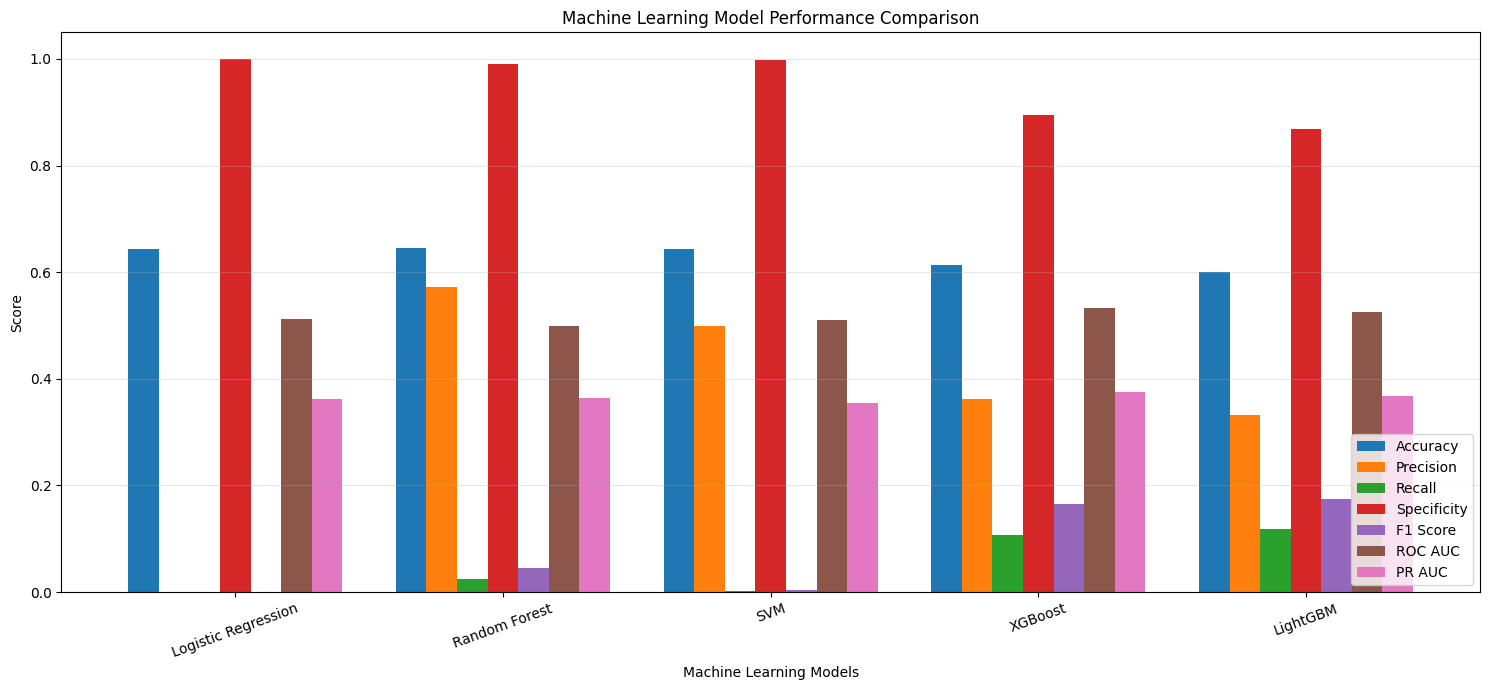

In [12]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1 Score",
    "ROC AUC",
    "PR AUC"
]

results_plot = results_df.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(15, 7),
    width=0.8
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


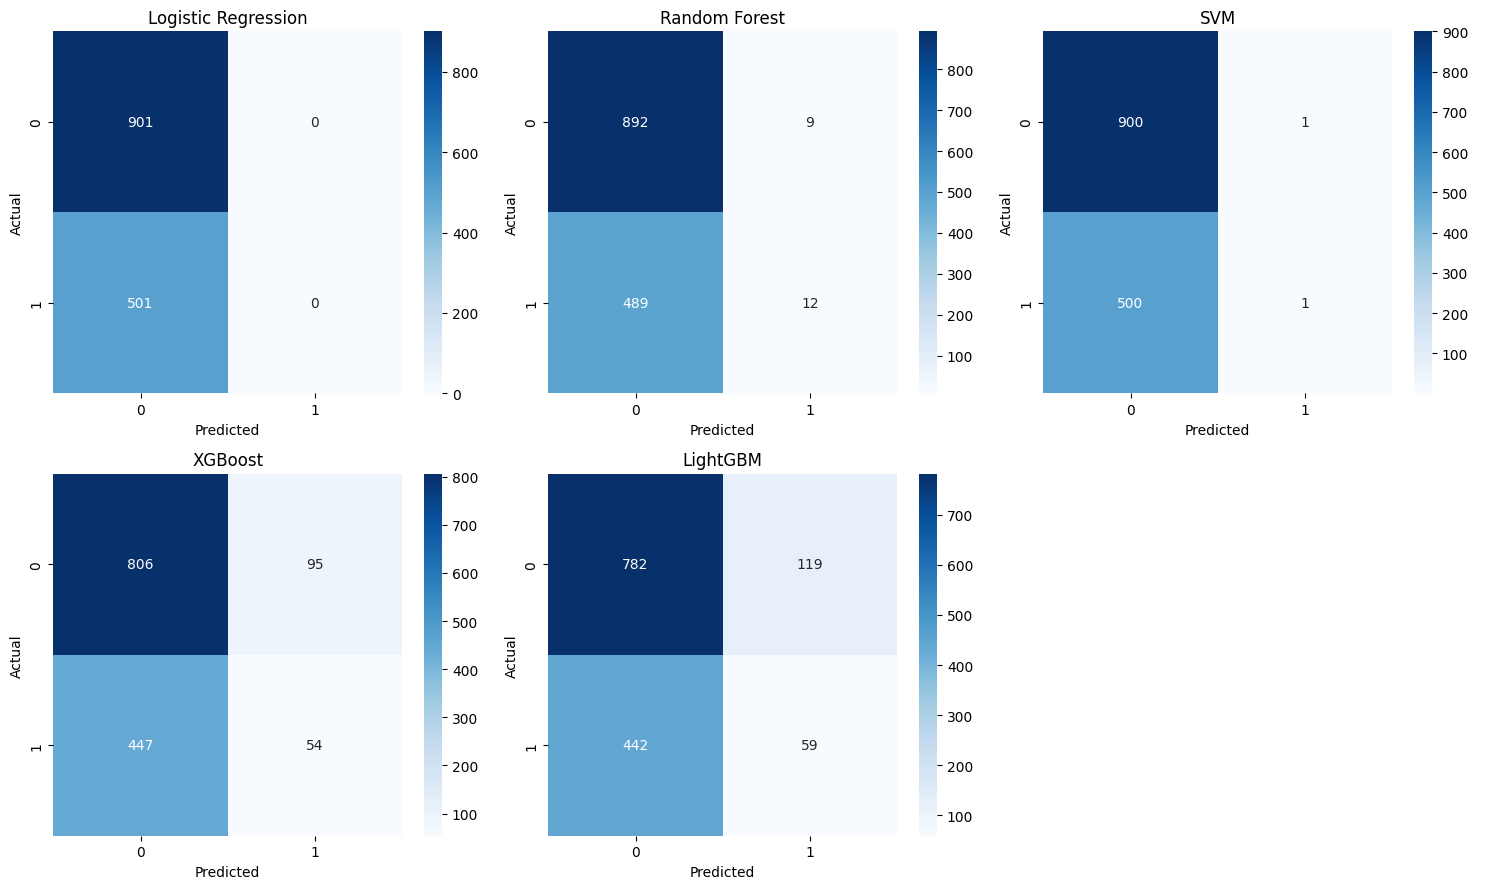

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, pipeline) in enumerate(trained_models.items()):

    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

for j in range(len(trained_models), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


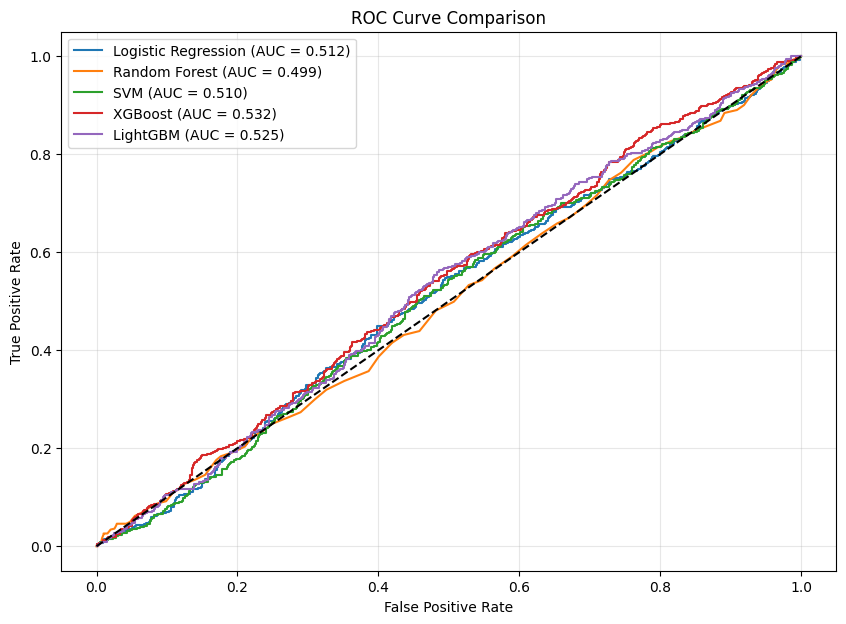

In [14]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 7))

for name, pipeline in trained_models.items():

    y_prob = pipeline.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {roc_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

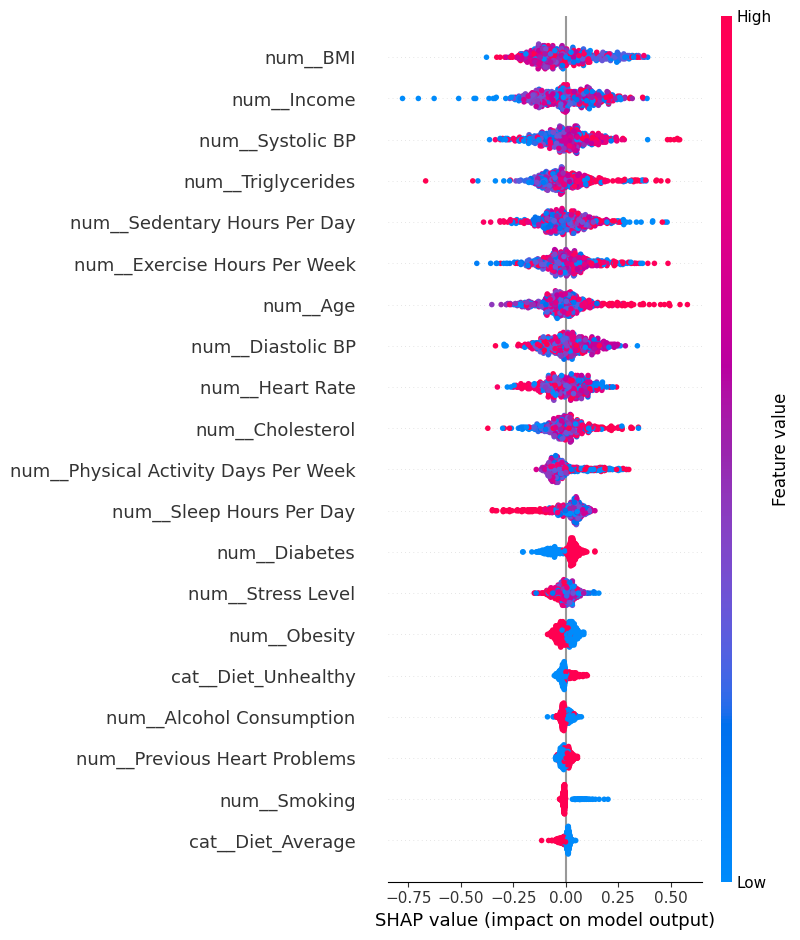

In [15]:
import shap

xgb_pipeline = trained_models["XGBoost"]

# Transform the test data
X_test_transformed = xgb_pipeline.named_steps[
    "preprocessor"
].transform(X_test)

feature_names = (
    xgb_pipeline.named_steps[
        "preprocessor"
    ].get_feature_names_out()
)

# SHAP explainer
explainer = shap.TreeExplainer(
    xgb_pipeline.named_steps["classifier"]
)

shap_values = explainer(
    X_test_transformed[:500]
)

shap.summary_plot(
    shap_values.values,
    X_test_transformed[:500],
    feature_names=feature_names
)

In [16]:
best_model_name = results_df.sort_values(
    by="ROC AUC",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

joblib.dump(
    best_model,
    "heart_attack_baseline_model.pkl"
)

print("Model saved successfully!")

Best model: XGBoost
Model saved successfully!


In [17]:
files.download("heart_attack_baseline_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>